# BTC price predictor

Guesses for the next **hour**, **week** and **month** (30 days) with the model in `btc_model.py` (the same one the website uses):
- the average price of the period, and whether it goes up or down
- how big the move will be, and an 80% range for the price
- which guesses are *confident*

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from btc_data import load_prices
from btc_model import PERIODS, build_dataset, forecast, report, walk_forward

## 1. Data
Hourly BTC/USDT prices from Binance, 2018 until now (UTC).

In [2]:
prices = load_prices()
print(f"{prices.index[0]} -> {prices.index[-1]}")
prices.tail()

2018-01-01 00:00:00 -> 2026-10-26 11:00:00


,Open,High,Low,Close,Volume
Open time,,,,,
2026-10-26 07:00:00,80130.01,80235.25,79958.00,80046.71,497.86877
2026-10-26 08:00:00,80046.72,80418.67,79673.80,80235.14,731.23378
2026-10-26 09:00:00,80235.14,80575.45,80187.75,80538.53,421.07984
2026-10-26 10:00:00,80538.53,80538.54,80370.00,80370.01,264.65931
2026-10-26 11:00:00,80370.00,80540.01,80242.82,80416.01,581.98560


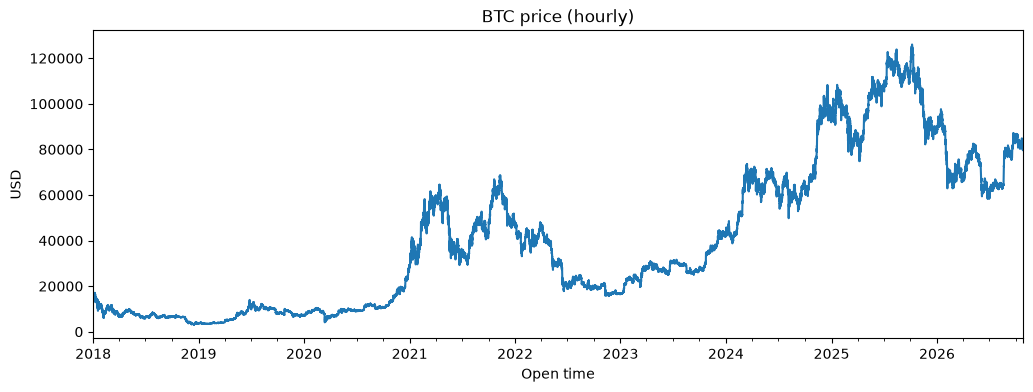

In [3]:
prices["Close"].plot(figsize=(12, 4), title="BTC price (hourly)", ylabel="USD")
plt.show()

## 2. Features
Two models, each with its own inputs:
- **change model** (up or down): % change of the price and volume in each of the last 4 periods
- **move model** (how big the move will be): recent size of the moves, high-low range, hour of day and day of week

In [4]:
data, features = build_dataset(prices, PERIODS["hour"])
print("change model:", features["change"])
print("move model:  ", features["move"])
data.dropna().tail(3)

change model: ['price1', 'volume1', 'price2', 'volume2', 'price3', 'volume3', 'price4', 'volume4']
move model:   ['move1', 'move2', 'move3', 'move4', 'move_24h', 'move_168h', 'move_720h', 'range', 'hour_0', 'hour_1', 'hour_2', 'hour_3', 'hour_4', 'hour_5', 'hour_6', 'hour_7', 'hour_8', 'hour_9', 'hour_10', 'hour_11', 'hour_12', 'hour_13', 'hour_14', 'hour_15', 'hour_16', 'hour_17', 'hour_18', 'hour_19', 'hour_20', 'hour_21', 'hour_22', 'hour_23', 'day_0', 'day_1', 'day_2', 'day_3', 'day_4', 'day_5', 'day_6']


,price1,volume1,price2,volume2,price3,volume3,price4,volume4,move1,move2,...,hour_23,day_0,day_1,day_2,day_3,day_4,day_5,day_6,last_price,change
Open time,,,,,,,,,,,,,,,,,,,,,
2026-10-26 08:00:00,0.002354,0.384397,-0.001040,0.439504,-0.001661,0.019113,0.001614,-0.443866,-6.051214,-6.867996,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,80235.14,0.003781
2026-10-26 09:00:00,0.003781,-0.551911,0.002354,0.384397,-0.001040,0.439504,-0.001661,0.019113,-5.577433,-6.051214,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,80538.53,-0.002092
2026-10-26 10:00:00,-0.002092,-0.464379,0.003781,-0.551911,0.002354,0.384397,-0.001040,0.439504,-6.168959,-5.577433,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,80370.01,0.000572


## 3. Test with walk-forward
Guess every period from `TEST_START` until now: every hour, every week (from Monday) and every month (30 days from the 1st).
The model re-learns at the start of every month, only from what was known then.

In [5]:
TEST_START = pd.Timestamp("2021-01-01")

results = {}
for name, hours in PERIODS.items():
    data, features = build_dataset(prices, hours)
    results[name] = walk_forward(data, features, name, TEST_START, prices.index[-1])

## 4. How good is it?
- **right direction %:** 50% is a coin flip. *Chance it's luck* under 5% means the result is probably real.
- **confident:** the 20% of guesses where the model expects the biggest move compared with how wild the market is
- **inside 80% range %:** should be about 80
- **move size better than average guess %:** above 0 means the move guess beats always guessing the average move

In [6]:
pd.DataFrame({name: report(result) for name, result in results.items()}).round(2)

,hour,week,month
guesses,50939.00,303.00,69.00
accuracy %,99.62,96.33,91.80
same-as-last-price %,99.62,96.44,92.49
right direction %,52.61,47.52,57.97
chance it's luck %,0.00,82.10,11.42
confident guesses,11212.00,96.00,15.00
confident right direction %,54.99,48.96,60.00
confident chance it's luck %,0.00,62.02,30.36
inside 80% range %,79.42,75.91,79.71
move size better than average guess %,22.63,10.22,-6.92


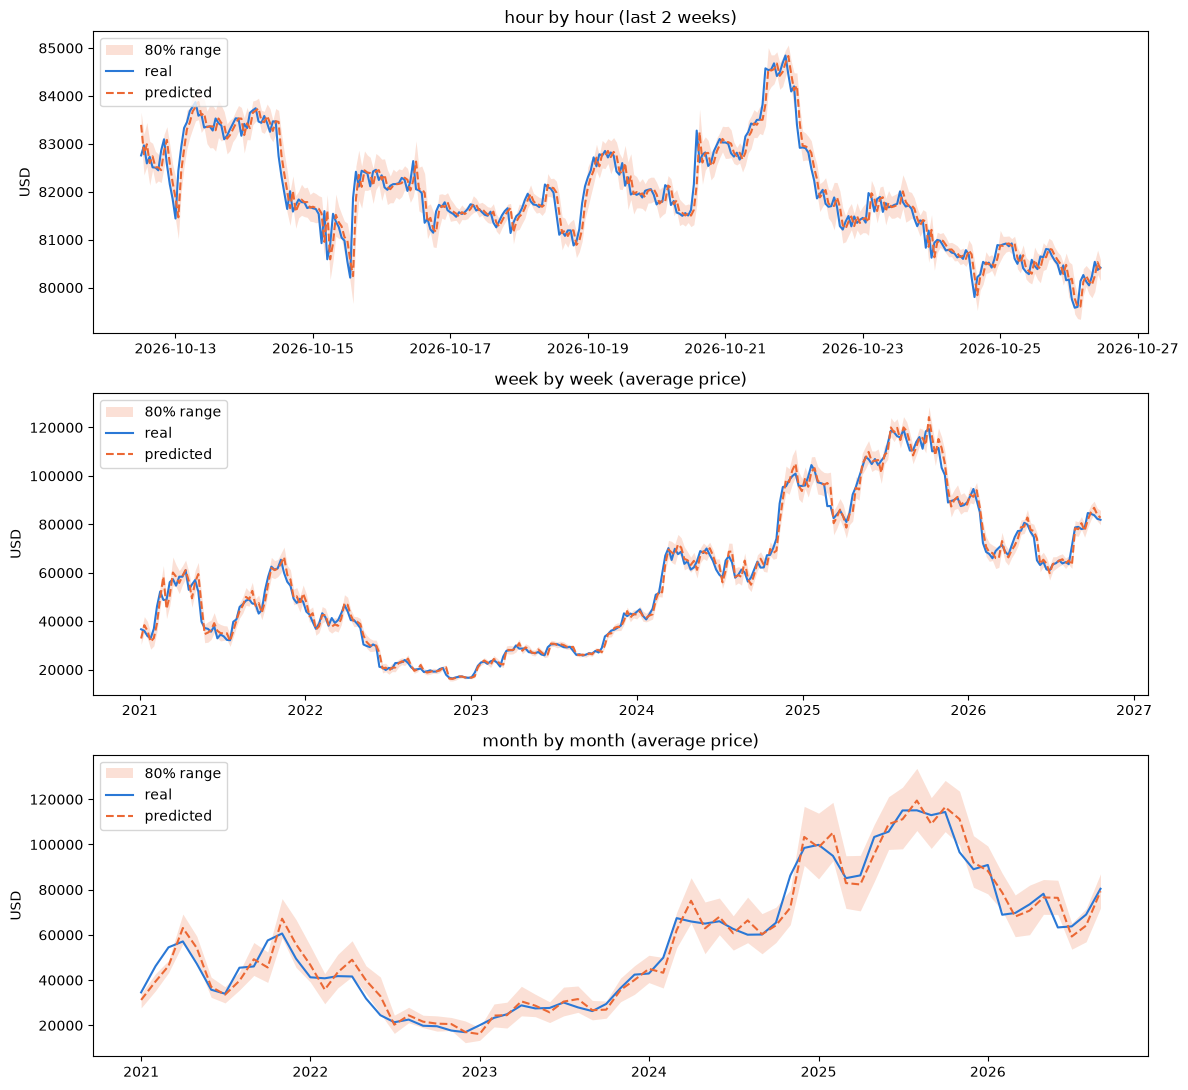

In [7]:
fig, axes = plt.subplots(3, 1, figsize=(12, 11))
for ax, (name, result) in zip(axes, results.items()):
    shown = result.tail(24 * 14) if name == "hour" else result  # hours: last 2 weeks only, or the lines blur together
    ax.fill_between(shown.index, shown["low"], shown["high"], color="#eb6834", alpha=0.2, lw=0, label="80% range")
    ax.plot(shown.index, shown["real"], color="#2a78d6", lw=1.5, label="real")
    ax.plot(shown.index, shown["predicted"], color="#eb6834", lw=1.5, ls="--", label="predicted")
    ax.set_title(f"{name} by {name}" + (" (last 2 weeks)" if name == "hour" else " (average price)"))
    ax.set_ylabel("USD")
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

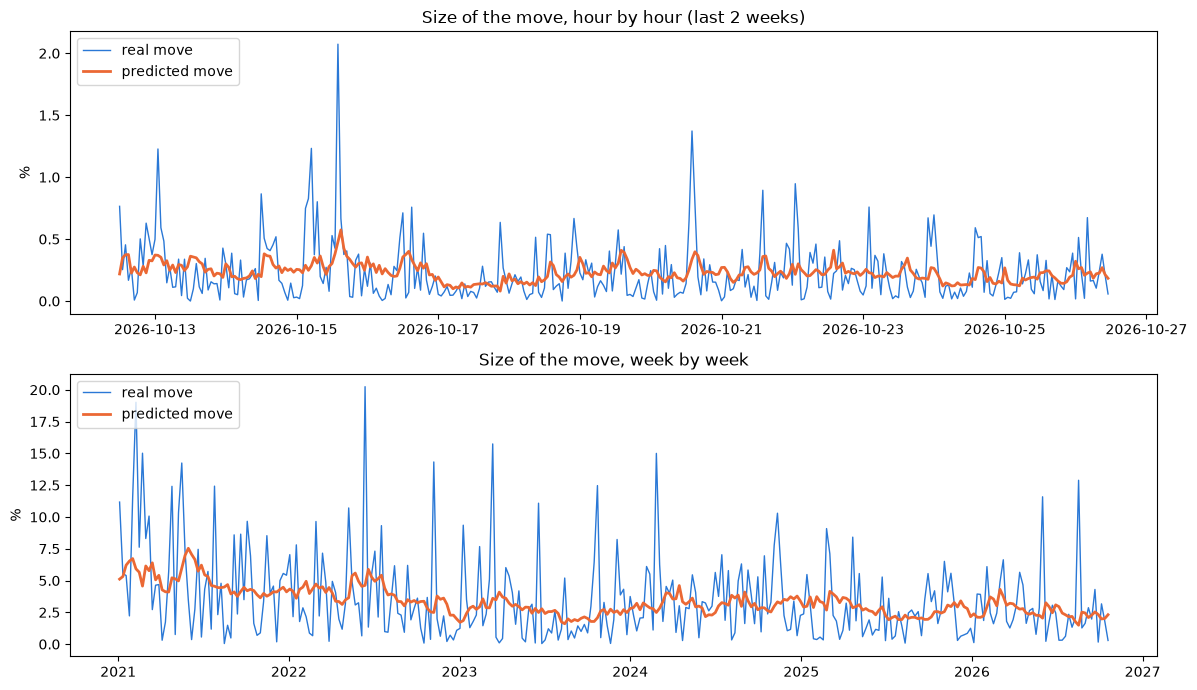

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7))
for ax, name in zip(axes, ["hour", "week"]):
    shown = results[name].tail(24 * 14) if name == "hour" else results[name]
    ax.plot(shown.index, shown["change"].abs() * 100, color="#2a78d6", lw=1, label="real move")
    ax.plot(shown.index, shown["move"] * 100, color="#eb6834", lw=2, label="predicted move")
    ax.set_title(f"Size of the move, {name} by {name}" + (" (last 2 weeks)" if name == "hour" else ""))
    ax.set_ylabel("%")
    ax.legend(loc="upper left")
fig.tight_layout()
plt.show()

## 5. Guess the future
Learn from all prices so far, then guess the next hour, week and month.

In [9]:
guesses = {}
for name, hours in PERIODS.items():
    data, features = build_dataset(prices, hours)
    guesses[name] = forecast(data, features)

future = pd.DataFrame(guesses).T.infer_objects()
future["move %"] = future["move"] * 100
print(f"Based on prices until {prices.index[-1]} UTC")
future[["predicted", "low", "high", "move %", "confident"]].round(2)

Based on prices until 2026-10-26 11:00:00 UTC


,predicted,low,high,move %,confident
hour,80421.02,80118.80,80716.68,0.25,False
week,80705.58,77917.44,83607.06,2.27,False
month,83410.69,75369.50,91897.23,6.28,True


## Notes
- **Hour:** the direction edge is small but real, and bigger for confident guesses. It is mostly one simple rule: "guess the opposite of the last hour" scores about the same (52.7% vs 52.6%). Still too small to beat trading fees.
- **Week and month:** too few guesses to tell skill from luck.
- **Move size and 80% range** work far better than the direction: how wild the market will be is much easier to guess than which way it goes.
- Try changing `TEST_START`, or `WINDOW`, `RANGE` and `CONFIDENT_SHARE` at the top of `btc_model.py`.